## 0. Setup




In [1]:
import sys, warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT / "scripts"))
import xbd_viz as V

V.use_theme()
warnings.filterwarnings("ignore")
pd.set_option("display.width", 200, "display.max_columns", 60)

GEO = ROOT / "geotiffs"
CACHE = ROOT / "cache"
assert CACHE.exists(), "cache/ ausente — rode: python scripts/build_index.py"

images = pd.read_parquet(CACHE / "images.parquet")       # 1 linha por imagem
buildings = pd.read_parquet(CACHE / "buildings.parquet") # 1 linha por poligono
registration = pd.read_parquet(CACHE / "registration.parquet")
band_stats = pd.read_parquet(CACHE / "band_stats.parquet")

# categorias -> str facilita agregacoes ad-hoc
for df in (images, buildings):
    for c in df.select_dtypes("category").columns:
        df[c] = df[c].astype(str)

post = images[images.phase == "post"]
DMG = ["no-damage", "minor-damage", "major-damage", "destroyed"]
NDMG = [f"n_{c}" for c in DMG]

print(f"images      {images.shape}")
print(f"buildings   {buildings.shape}")
print(f"registration{registration.shape}")

images      (22068, 43)
buildings   (850736, 15)
registration(425368, 7)


---
## 1. Inventario: quantas imagens, quanto pesa



In [2]:
n_img = len(images)
n_scenes = images.scene_id.nunique()
tif_gb = images.tif_bytes.sum() / 1e9
json_gb = images.json_bytes.sum() / 1e9

resumo = pd.Series({
    "Imagens (GeoTIFF)":            f"{n_img:,}",
    "Pares pre/pos (cenas)":        f"{n_scenes:,}",
    "Poligonos de edificacao":      f"{len(buildings):,}",
    "Desastres distintos":          images.disaster.nunique(),
    "Tipos de desastre":            images.disaster_type.nunique(),
    "Tamanho — imagens":            f"{tif_gb:,.1f} GB",
    "Tamanho — labels JSON":        f"{json_gb*1000:,.0f} MB",
    "Tamanho — total extraido":     f"{tif_gb + json_gb:,.1f} GB",
    "Tarball comprimido":           "52 GB",
}, name="valor").to_frame()
resumo

,valor
Imagens (GeoTIFF),"22,068"
Pares pre/pos (cenas),"11,034"
Poligonos de edificacao,"850,736"
Desastres distintos,19
Tipos de desastre,6
Tamanho — imagens,139.1 GB
Tamanho — labels JSON,790 MB
Tamanho — total extraido,139.9 GB
Tarball comprimido,52 GB


In [3]:
por_split = (images.groupby("split")
             .agg(imagens=("stem", "size"),
                  cenas=("scene_id", "nunique"),
                  GB=("tif_bytes", lambda s: s.sum() / 1e9),
                  edificacoes=("n_buildings", "sum"),
                  desastres=("disaster", "nunique"))
             .loc[["tier1", "tier3", "hold", "test"]])
por_split["% imagens"] = (por_split.imagens / n_img * 100).round(1)
por_split.round(1)

,imagens,cenas,GB,edificacoes,desastres,% imagens
split,,,,,,
tier1,5598,2799,35.3,325574,10,25.4
tier3,12738,6369,80.3,306654,9,57.7
hold,1866,933,11.8,108784,10,8.5
test,1866,933,11.8,109724,10,8.5


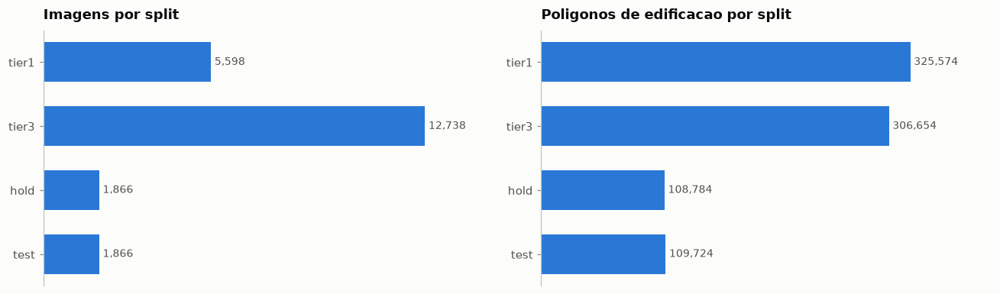

In [4]:
# Duas medidas de escala diferente => dois paineis, nunca dois eixos y no mesmo grafico.
fig, axes = plt.subplots(1, 2, figsize=(12, 3.6))
ordem = por_split.index.tolist()
y = np.arange(len(ordem))[::-1]

b1 = axes[0].barh(y, por_split.imagens, height=0.62, color=V.CATEGORICAL[0])
axes[0].set_title("Imagens por split")
V.bar_labels(axes[0], b1)
axes[0].set_xlim(0, por_split.imagens.max() * 1.18)

b2 = axes[1].barh(y, por_split.edificacoes, height=0.62, color=V.CATEGORICAL[0])
axes[1].set_title("Poligonos de edificacao por split")
V.bar_labels(axes[1], b2)
axes[1].set_xlim(0, por_split.edificacoes.max() * 1.22)

for ax in axes:
    ax.set_yticks(y, ordem)
    ax.grid(axis="x"); ax.grid(axis="y", visible=False)
    ax.set_xticks([])
    ax.spines["bottom"].set_visible(False)
fig.tight_layout()

---
## 2. Formato dos arquivos

In [5]:
formato = pd.Series({
    "Dimensoes":      f"{images.width.iloc[0]} x {images.height.iloc[0]} px (100% das imagens)",
    "Bandas":         f"{images.bands.iloc[0]} (RGB)",
    "dtype":          images.dtype.iloc[0],
    "CRS":            images.crs.iloc[0],
    "nodata":         images.nodata.iloc[0],
    "Compressao":     str(images.compression.iloc[0]),
    "Bytes/arquivo":  f"{images.tif_bytes.iloc[0]:,}",
}, name="valor").to_frame()

# confirma que sao mesmo constantes, nao so a primeira linha
constantes = {c: images[c].nunique() for c in ["width","height","bands","dtype","crs","nodata","compression","tif_bytes"]}
print("valores distintos por coluna (1 = constante em todo o dataset):", constantes)
formato

valores distintos por coluna (1 = constante em todo o dataset): {'width': 1, 'height': 1, 'bands': 1, 'dtype': 1, 'crs': 1, 'nodata': 1, 'compression': 1, 'tif_bytes': 1}


,valor
Dimensoes,1024 x 1024 px (100% das imagens)
Bandas,3 (RGB)
dtype,int16
CRS,EPSG:4326
nodata,-99.0
Compressao,None
Bytes/arquivo,"6,304,308"


In [6]:
print(f"amostra de {len(band_stats)} imagens (lidas pixel a pixel)")
print(f"  minimo global : {band_stats['min'].min():.0f}")
print(f"  maximo global : {band_stats['max'].max():.0f}")
print(f"  todas cabem em uint8 : {band_stats.fits_uint8.all()}")

atual = images.tif_bytes.sum() / 1e9
print(f"\nNo disco hoje          : {atual:6.1f} GB")
print(f"Cast para uint8        : {atual/2:6.1f} GB   (-50%, sem perda)")
print(f"uint8 + DEFLATE        : ~{atual/2*0.55:5.1f} GB   (-73%, estimativa ~45% de ganho)")

amostra de 399 imagens (lidas pixel a pixel)
  minimo global : 0
  maximo global : 255
  todas cabem em uint8 : True

No disco hoje          :  139.1 GB
Cast para uint8        :   69.6 GB   (-50%, sem perda)
uint8 + DEFLATE        : ~ 38.3 GB   (-73%, estimativa ~45% de ganho)


In [7]:
print(images[["m_per_px_x", "m_per_px_y"]].describe().loc[["mean","min","max"]].round(3))
razao = (images.m_per_px_x / images.m_per_px_y)
print(f"\nrazao m/px X:Y — mediana {razao.median():.3f}, min {razao.min():.3f}, max {razao.max():.3f}")
print("=> as edificacoes aparecem horizontalmente comprimidas em relacao ao terreno,")
print("   e o fator de compressao varia com a latitude do desastre.")

      m_per_px_x  m_per_px_y
mean       0.425       0.505
min        0.395       0.496
max        0.500       0.513

razao m/px X:Y — mediana 0.833, min 0.771, max 1.007
=> as edificacoes aparecem horizontalmente comprimidas em relacao ao terreno,
   e o fator de compressao varia com a latitude do desastre.


---
## 3. Quantas classes

In [8]:
tax = pd.DataFrame([
    ("feature_type",   buildings.subtype.notna().sum(), 1, "apenas 'building' — nao ha outras feicoes"),
    ("dano (subtype)", (buildings.phase == "post").sum(), 4, "no-damage < minor < major < destroyed (ordinal) + 'un-classified'"),
    ("disaster_type",  len(images), images.disaster_type.nunique(), ", ".join(sorted(images.disaster_type.unique()))),
    ("disaster",       len(images), images.disaster.nunique(), "eventos nomeados (ex.: palu-tsunami)"),
], columns=["taxonomia", "n_amostras", "n_classes", "observacao"]).set_index("taxonomia")
tax

,n_amostras,n_classes,observacao
taxonomia,,,
feature_type,850736,1,apenas 'building' — nao ha outras feicoes
dano (subtype),425368,4,no-damage < minor < major < destroyed (ordinal...
disaster_type,22068,6,"earthquake, fire, flooding, tsunami, volcano, ..."
disaster,22068,19,eventos nomeados (ex.: palu-tsunami)


In [9]:
cls_cnt = buildings[buildings.phase == "post"].subtype.value_counts()
cls = cls_cnt.reindex(V.DAMAGE_ORDER).to_frame("edificacoes")
cls["%"] = (cls.edificacoes / cls.edificacoes.sum() * 100).round(2)
cls["razao_vs_no-damage"] = (cls_cnt["no-damage"] / cls.edificacoes).round(1)
cls

,edificacoes,%,razao_vs_no-damage
subtype,,,
no-damage,313033,73.59,1.0
minor-damage,36860,8.67,8.5
major-damage,29904,7.03,10.5
destroyed,31560,7.42,9.9
un-classified,14011,3.29,22.3


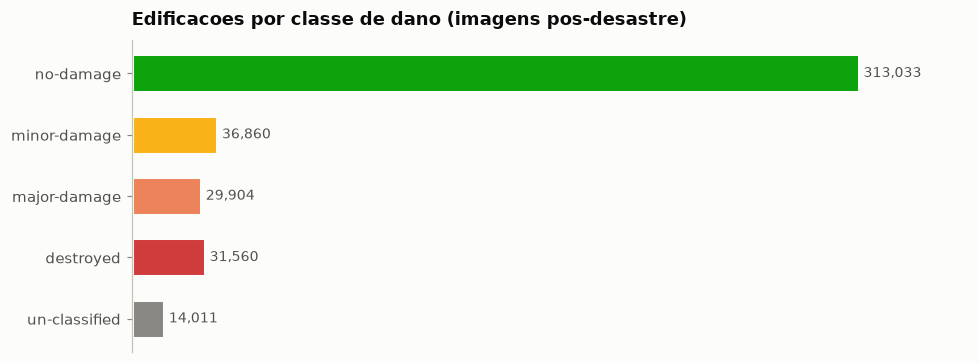

In [10]:
# Escala de severidade = paleta de status. Rotulos de eixo + valores diretos carregam a
# identidade; a cor so reforca. (A tabela acima e a "table view" exigida pelo contraste.)
fig, ax = plt.subplots(figsize=(9, 3.4))
y = np.arange(len(V.DAMAGE_ORDER))[::-1]
vals = cls.edificacoes.values
bars = ax.barh(y, vals, height=0.62,
               color=[V.DAMAGE_COLORS[c] for c in V.DAMAGE_ORDER],
               edgecolor=V.SURFACE, linewidth=2)
ax.set_yticks(y, V.DAMAGE_ORDER)
ax.set_title("Edificacoes por classe de dano (imagens pos-desastre)")
V.bar_labels(ax, bars)
ax.set_xlim(0, vals.max() * 1.15)
ax.set_xticks([]); ax.grid(False)
ax.spines["bottom"].set_visible(False)
fig.tight_layout()

---
## 4. Desastres: 19 eventos, 6 tipos, distribuicao muito desigual

In [11]:
ev = (images.groupby(["disaster_type", "disaster"])
      .agg(imagens=("stem", "size"), cenas=("scene_id", "nunique"))
      .join(post.groupby(["disaster_type", "disaster"])[NDMG].sum()))
ev["edificacoes"] = ev[NDMG].sum(1)
ev["splits"] = images.groupby(["disaster_type","disaster"]).split.agg(lambda s: "+".join(sorted(set(s))))
ev.sort_values("imagens", ascending=False)[["imagens","cenas","edificacoes","splits"]]

imagens  cenas  edificacoes           splits
disaster_type disaster                                                         
fire          portugal-wildfire       3738   1869        22349            tier3
              pinery-bushfire         3690   1845         5437            tier3
              socal-fire              2806   1403        18276  hold+test+tier1
              woolsey-fire            1756    878         6829            tier3
flooding      nepal-flooding          1238    619        41582            tier3
wind          hurricane-michael       1100    550        35128  hold+test+tier1
flooding      hurricane-florence      1092    546        10728  hold+test+tier1
              hurricane-harvey        1044    522        37374  hold+test+tier1
              midwest-flooding         890    445        13423  hold+test+tier1
wind          hurricane-matthew        810    405        22630  hold+test+tier1
fire          santa-rosa-wildfire      754    377        21869  hold+test+tier1
wind          tuscaloosa-tornado       686    343        14098            tier3
volcano       lower-puna-volcano       582    291         2856            tier3
wind          moore-tornado            454    227        22372            tier3
tsunami       palu-tsunami             392    196        55178  hold+test+tier1
earthquake    mexico-earthquake        386    193        51362  hold+test+tier1
wind          joplin-tornado           298    149        14696            tier3
tsunami       sunda-tsunami            296    148        14357            tier3
volcano       guatemala-volcano         56     28          813  hold+test+tier1

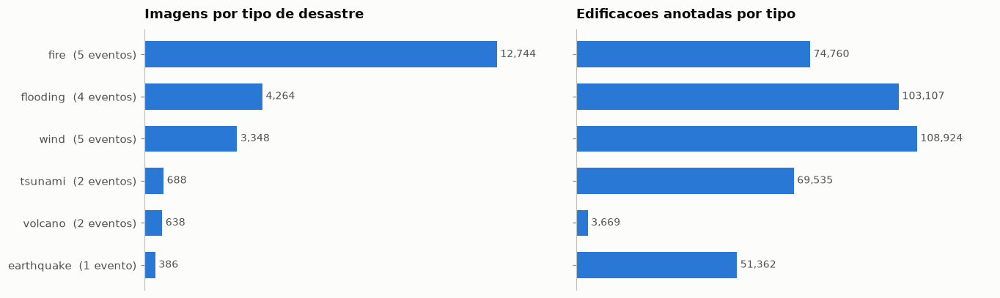

In [12]:
tipos = (images.groupby("disaster_type")
         .agg(imagens=("stem","size"), eventos=("disaster","nunique"))
         .sort_values("imagens", ascending=False))

fig, axes = plt.subplots(1, 2, figsize=(12.5, 3.8))
y = np.arange(len(tipos))[::-1]
b = axes[0].barh(y, tipos.imagens, height=0.62, color=V.CATEGORICAL[0])
axes[0].set_yticks(y, [f"{t}  ({n} evento{'s' if n>1 else ''})" for t, n in zip(tipos.index, tipos.eventos)])
axes[0].set_title("Imagens por tipo de desastre")
V.bar_labels(axes[0], b)
axes[0].set_xlim(0, tipos.imagens.max()*1.18)

ed = post.groupby("disaster_type")[NDMG].sum().sum(1).reindex(tipos.index)
b2 = axes[1].barh(y, ed, height=0.62, color=V.CATEGORICAL[0])
axes[1].set_yticks(y, [""]*len(y))
axes[1].set_title("Edificacoes anotadas por tipo")
V.bar_labels(axes[1], b2)
axes[1].set_xlim(0, ed.max()*1.22)

for ax in axes:
    ax.set_xticks([]); ax.grid(False); ax.spines["bottom"].set_visible(False)
fig.tight_layout()

---
## 5. A distribuicao de classes entre desastres

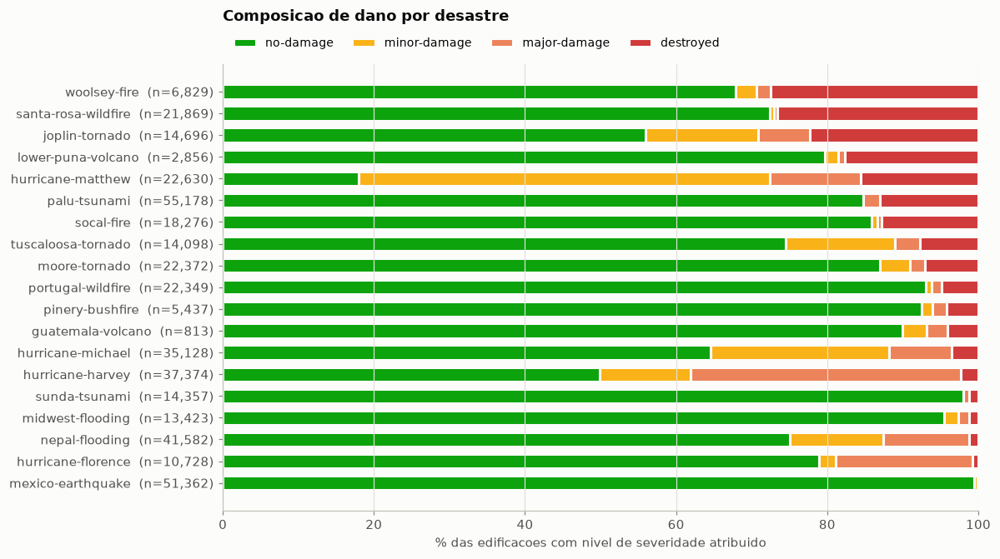

In [13]:
per = post.groupby("disaster")[NDMG].sum()
per.columns = DMG
per = per[per.sum(1) > 0]
pct = per.div(per.sum(1), axis=0) * 100
pct = pct.loc[pct["destroyed"].sort_values().index]

fig, ax = plt.subplots(figsize=(11, 6.2))
y = np.arange(len(pct))
left = np.zeros(len(pct))
for c in DMG:
    ax.barh(y, pct[c], left=left, height=0.66, label=c,
            color=V.DAMAGE_COLORS[c], edgecolor=V.SURFACE, linewidth=2)  # gap de 2px entre segmentos
    left += pct[c].values
ax.set_yticks(y, [f"{d}  (n={per.loc[d].sum():,.0f})" for d in pct.index])
ax.set_xlim(0, 100)
ax.set_xlabel("% das edificacoes com nivel de severidade atribuido")
ax.set_title("Composicao de dano por desastre", pad=34)
ax.legend(ncols=4, loc="lower left", bbox_to_anchor=(0, 1.01), columnspacing=1.6)
ax.grid(axis="x"); ax.grid(axis="y", visible=False)
fig.tight_layout()

In [14]:
# table view do grafico acima (a paleta de status exige rotulo/tabela, nunca cor sozinha)
pct.round(1).assign(total=per.sum(1).astype(int)).sort_values("total", ascending=False)

,no-damage,minor-damage,major-damage,destroyed,total
disaster,,,,,
palu-tsunami,84.8,0.0,2.1,13.1,55178
mexico-earthquake,99.5,0.4,0.1,0.0,51362
nepal-flooding,75.1,12.3,11.4,1.2,41582
hurricane-harvey,49.9,12.1,35.8,2.3,37374
hurricane-michael,64.6,23.6,8.3,3.5,35128
hurricane-matthew,17.9,54.5,12.0,15.6,22630
moore-tornado,87.0,4.0,2.0,7.1,22372
portugal-wildfire,93.0,0.8,1.3,4.9,22349
santa-rosa-wildfire,72.4,0.6,0.4,26.6,21869


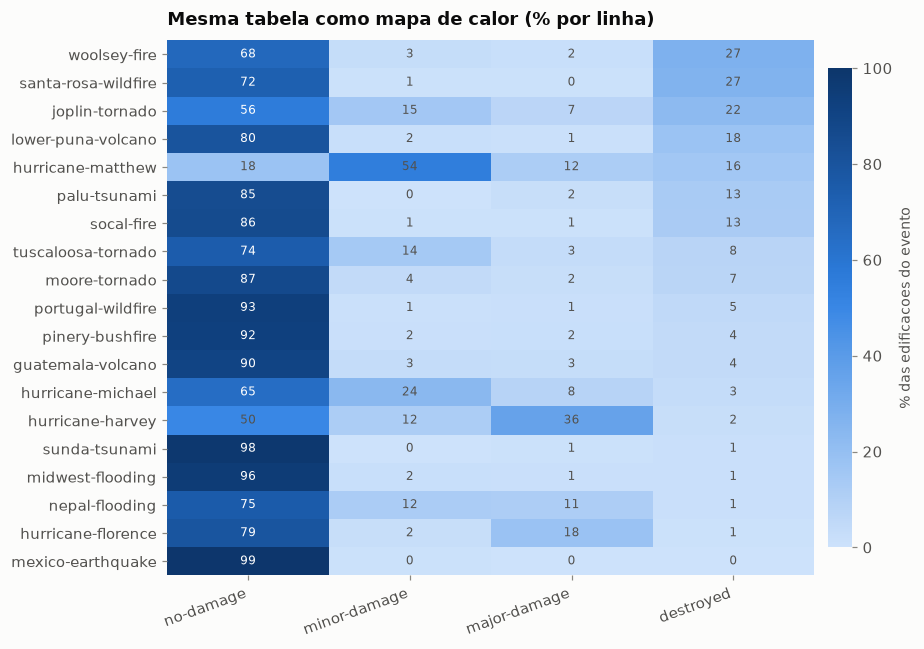

In [15]:
fig, ax = plt.subplots(figsize=(8.5, 6))
m = pct.loc[pct.index[::-1]]
im_ = ax.imshow(m.values, cmap=V.seq_cmap(), aspect="auto", vmin=0, vmax=100)
ax.set_xticks(range(len(DMG)), DMG, rotation=20, ha="right")
ax.set_yticks(range(len(m)), m.index)
ax.set_title("Mesma tabela como mapa de calor (% por linha)")
ax.grid(False)
for s in ax.spines.values():
    s.set_visible(False)
for i in range(m.shape[0]):
    for j in range(m.shape[1]):
        v = m.values[i, j]
        ax.text(j, i, f"{v:.0f}", ha="center", va="center", fontsize=8,
                color="#ffffff" if v > 55 else V.INK_2)
cb = fig.colorbar(im_, ax=ax, fraction=0.035, pad=0.02)
cb.set_label("% das edificacoes do evento", color=V.INK_2, fontsize=9)
cb.outline.set_visible(False)
fig.tight_layout()

---
## 6. Geometria dos objetos: tamanho, densidade, cobertura


In [16]:
dens = images.groupby("phase").n_buildings.describe(percentiles=[.25,.5,.75,.9,.99]).round(1)
vazias = (post.n_buildings == 0)
print(dens.loc[["pre"]].to_string(), "\n")
print(f"imagens sem nenhuma edificacao : {vazias.sum():,} de {len(post):,} cenas  ({vazias.mean()*100:.1f}%)")
print(f"cena mais densa                : {post.n_buildings.max():,} edificacoes")
print("\nfracao de cenas vazias por split:")
print((post.assign(vazia=post.n_buildings == 0).groupby("split").vazia.mean() * 100).round(1).to_string())

         count  mean   std  min  25%  50%   75%    90%    99%     max
phase                                                                
pre    11034.0  38.6  89.9  0.0  0.0  6.0  35.0  112.7  410.7  1843.0 

imagens sem nenhuma edificacao : 3,858 de 11,034 cenas  (35.0%)
cena mais densa                : 1,843 edificacoes

fracao de cenas vazias por split:
split
hold     18.2
test     19.4
tier1    18.4
tier3    47.0


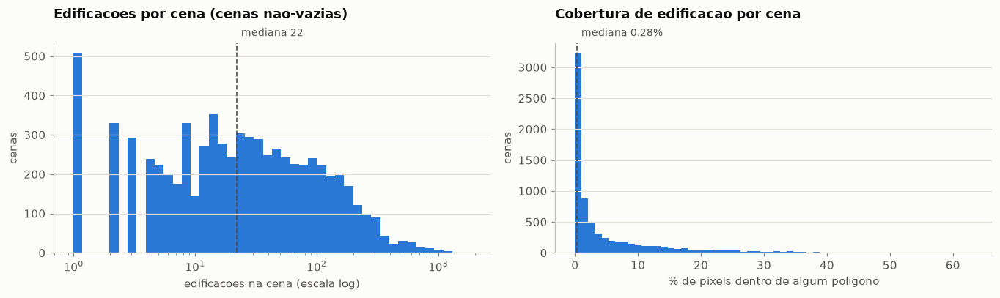

In [17]:
fig, axes = plt.subplots(1, 2, figsize=(12.5, 3.8))

nb = post.n_buildings
axes[0].hist(nb[nb > 0], bins=np.logspace(0, np.log10(nb.max()), 45), color=V.CATEGORICAL[0])
axes[0].set_xscale("log")
axes[0].set_title("Edificacoes por cena (cenas nao-vazias)", pad=22)
axes[0].set_xlabel("edificacoes na cena (escala log)")
axes[0].set_ylabel("cenas")
V.ref_line(axes[0], nb[nb > 0].median(), f"mediana {nb[nb>0].median():.0f}")

cov = post.building_cover_frac * 100
axes[1].hist(cov[cov > 0], bins=60, color=V.CATEGORICAL[0])
axes[1].set_title("Cobertura de edificacao por cena", pad=22)
axes[1].set_xlabel("% de pixels dentro de algum poligono")
axes[1].set_ylabel("cenas")
V.ref_line(axes[1], cov.median(), f"mediana {cov.median():.2f}%")
fig.tight_layout()

In [18]:
print(f"cobertura media de edificacao : {post.building_cover_frac.mean()*100:.2f}% dos pixels")
print(f"razao fundo:objeto            : {(1-post.building_cover_frac.mean())/post.building_cover_frac.mean():.0f} : 1")

cobertura media de edificacao : 3.35% dos pixels
razao fundo:objeto            : 29 : 1


In [19]:
ar = buildings.area_px
q = ar.describe(percentiles=[.01,.05,.25,.5,.75,.95,.99]).round(1)
small  = (ar < 32**2).mean() * 100      # limiar "small" do COCO
tiny   = (ar < 16**2).mean() * 100
large  = (ar > 96**2).mean() * 100
print(q.to_string())
print(f"\narea em m2 — mediana {buildings.area_m2.median():.0f} m2, "
      f"p05 {buildings.area_m2.quantile(.05):.0f} m2, p95 {buildings.area_m2.quantile(.95):.0f} m2")
print(f"\nescala no criterio COCO:")
print(f"  small   (< 32x32 px) : {small:5.1f}%")
print(f"  tiny    (< 16x16 px) : {tiny:5.1f}%")
print(f"  large   (> 96x96 px) : {large:5.1f}%")
print(f"  bbox com lado < 10 px: {((buildings.bbox_w<10)|(buildings.bbox_h<10)).mean()*100:5.1f}%")

count    850736.0
mean        910.9
std        2158.4
min          16.3
1%           39.4
5%           76.3
25%         244.6
50%         575.0
75%        1126.0
95%        2359.5
99%        5703.9
max      398380.3

area em m2 — mediana 130 m2, p05 17 m2, p95 521 m2

escala no criterio COCO:
  small   (< 32x32 px) :  71.0%
  tiny    (< 16x16 px) :  26.2%
  large   (> 96x96 px) :   0.4%
  bbox com lado < 10 px:   8.2%


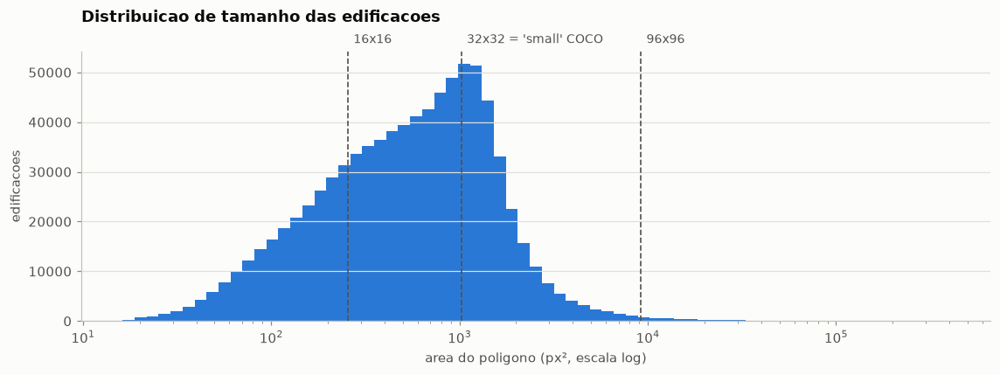

In [20]:
fig, ax = plt.subplots(figsize=(10.5, 4))
ax.hist(ar, bins=np.logspace(np.log10(ar.min()), np.log10(ar.max()), 70), color=V.CATEGORICAL[0])
ax.set_xscale("log")
ax.set_xlabel("area do poligono (px², escala log)")
ax.set_ylabel("edificacoes")
ax.set_title("Distribuicao de tamanho das edificacoes", pad=22)
for thr, lab in [(16**2, "16x16"), (32**2, "32x32 = 'small' COCO"), (96**2, "96x96")]:
    V.ref_line(ax, thr, lab)
fig.tight_layout()

In [21]:
# tamanho por classe de dano: destruido "encolhe"?
bp = buildings[buildings.phase == "post"]
por_classe = (bp.groupby("subtype").area_m2
              .describe(percentiles=[.5])[["count","mean","50%"]]
              .reindex(V.DAMAGE_ORDER).round(1)
              .rename(columns={"50%": "mediana_m2", "mean": "media_m2"}))
por_classe

,count,media_m2,mediana_m2
subtype,,,
no-damage,313033.0,205.0,132.5
minor-damage,36860.0,200.4,136.6
major-damage,29904.0,263.4,186.8
destroyed,31560.0,152.9,93.3
un-classified,14011.0,98.9,50.1


---
## 7. Condicoes de aquisicao

In [22]:
print("sensores:")
print((images.sensor.value_counts(normalize=True)*100).round(1).to_string())
print(f"\ncapturas distintas (catalog_id): {images.catalog_id.nunique()}")
print("\nGSD e angulos:")
images[["gsd","pan_resolution","off_nadir_angle","sun_elevation","sun_azimuth"]].describe(
    percentiles=[.05,.5,.95]).round(2).T

sensores:
sensor
WORLDVIEW02         66.1
GEOEYE01            23.6
WORLDVIEW03_VNIR     8.0
QUICKBIRD02          2.2

capturas distintas (catalog_id): 66

GSD e angulos:


,count,mean,std,min,5%,50%,95%,max
gsd,22068.0,2.12,0.32,1.24,1.66,2.09,2.65,3.15
pan_resolution,22068.0,0.53,0.08,0.31,0.41,0.52,0.66,0.78
off_nadir_angle,22068.0,22.92,8.33,3.56,8.89,24.51,34.38,44.19
sun_elevation,22068.0,57.35,13.24,32.06,34.96,62.01,71.92,74.70
sun_azimuth,22068.0,133.15,35.85,35.42,60.65,146.78,163.85,167.00


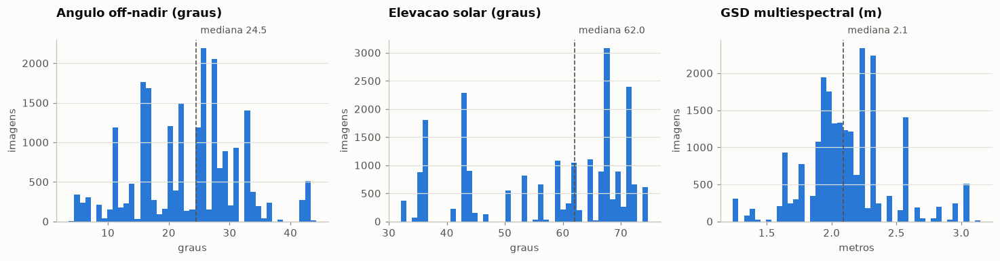

In [23]:
fig, axes = plt.subplots(1, 3, figsize=(13.5, 3.6))
specs = [("off_nadir_angle", "Angulo off-nadir (graus)", "graus"),
         ("sun_elevation",   "Elevacao solar (graus)",   "graus"),
         ("gsd",             "GSD multiespectral (m)",   "metros")]
for ax, (col, title, xl) in zip(axes, specs):
    ax.hist(images[col], bins=45, color=V.CATEGORICAL[0])
    ax.set_title(title, pad=22); ax.set_xlabel(xl); ax.set_ylabel("imagens")
    V.ref_line(ax, images[col].median(), f"mediana {images[col].median():.1f}")
fig.tight_layout()

In [24]:
piv = images.pivot_table(index=["split","scene_id"], columns="phase",
                         values=["off_nadir_angle","sun_elevation","capture_date"], aggfunc="first")
d_nadir = (piv[("off_nadir_angle","post")] - piv[("off_nadir_angle","pre")]).abs()
d_sun   = (piv[("sun_elevation","post")]   - piv[("sun_elevation","pre")]).abs()
gap     = (piv[("capture_date","post")] - piv[("capture_date","pre")]).dt.total_seconds() / 86400

delta = pd.DataFrame({
    "|Δ off-nadir| (graus)": d_nadir,
    "|Δ elevacao solar| (graus)": d_sun,
    "gap temporal (dias)": gap,
}).describe(percentiles=[.05,.5,.95]).round(1)
delta

,|Δ off-nadir| (graus),|Δ elevacao solar| (graus),gap temporal (dias)
count,11034.0,11034.0,11034.0
mean,10.4,9.4,305.5
std,7.5,9.3,361.2
min,0.4,1.5,22.0
5%,0.8,2.2,22.0
50%,9.1,6.8,304.0
95%,21.9,28.8,1219.0
max,34.6,40.4,1793.0


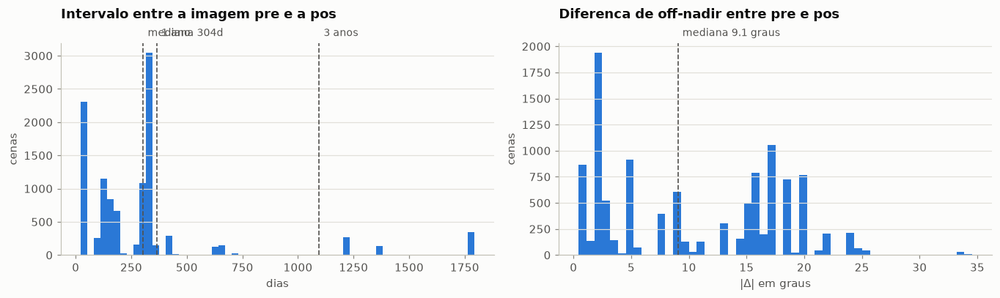

In [25]:
fig, axes = plt.subplots(1, 2, figsize=(12.5, 3.8))
axes[0].hist(gap, bins=60, color=V.CATEGORICAL[0])
axes[0].set_title("Intervalo entre a imagem pre e a pos", pad=22)
axes[0].set_xlabel("dias"); axes[0].set_ylabel("cenas")
for v, lab in [(gap.median(), f"mediana {gap.median():.0f}d"), (365, "1 ano"), (365*3, "3 anos")]:
    V.ref_line(axes[0], v, lab)

axes[1].hist(d_nadir, bins=50, color=V.CATEGORICAL[0])
axes[1].set_title("Diferenca de off-nadir entre pre e pos", pad=22)
axes[1].set_xlabel("|Δ| em graus"); axes[1].set_ylabel("cenas")
V.ref_line(axes[1], d_nadir.median(), f"mediana {d_nadir.median():.1f} graus")
fig.tight_layout()

In [26]:
print(f"gap temporal — mediana {gap.median():.0f} dias, p95 {gap.quantile(.95):.0f} dias, max {gap.max():.0f} dias")
print(f"cenas com mais de 1 ano entre pre e pos : {(gap > 365).mean()*100:.1f}%")
print(f"cenas com mais de 3 anos                : {(gap > 365*3).mean()*100:.1f}%")
print(f"nenhum gap negativo (pos antes do pre)  : {(gap < 0).sum() == 0}")

gap temporal — mediana 304 dias, p95 1219 dias, max 1793 dias
cenas com mais de 1 ano entre pre e pos : 13.6%
cenas com mais de 3 anos                : 6.8%
nenhum gap negativo (pos antes do pre)  : True


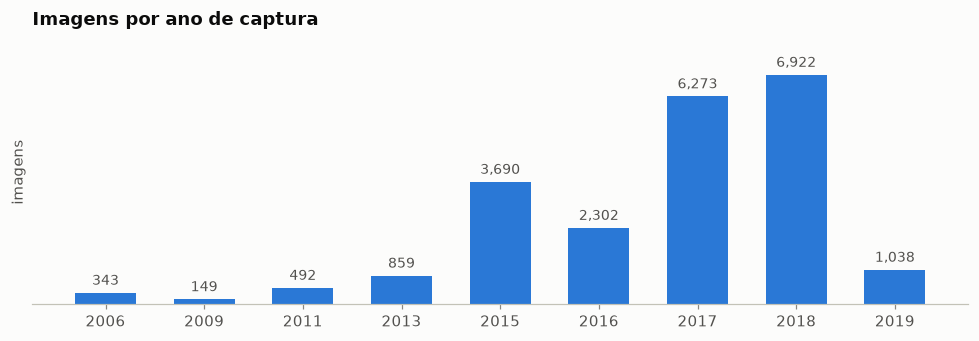

In [27]:
anos = images.capture_date.dt.year.value_counts().sort_index()
fig, ax = plt.subplots(figsize=(9, 3.2))
b = ax.bar(anos.index.astype(str), anos.values, width=0.62, color=V.CATEGORICAL[0])
ax.set_title("Imagens por ano de captura")
ax.set_ylabel("imagens")
V.bar_labels(ax, b)
ax.set_ylim(0, anos.max()*1.15)
ax.set_yticks([]); ax.grid(False)
ax.spines["left"].set_visible(False)
fig.tight_layout()

---
## 8. Estatisticas de pixel e constantes de normalizacao

Amostra estratificada por desastre, lida pixel a pixel.

In [28]:
mu  = [band_stats[f"mean_b{i}"].mean() for i in range(3)]
sd  = [band_stats[f"std_b{i}"].mean()  for i in range(3)]
between = [band_stats[f"mean_b{i}"].std() for i in range(3)]

norm = pd.DataFrame({
    "media (0-255)": np.round(mu, 2),
    "desvio intra-imagem": np.round(sd, 2),
    "desvio ENTRE imagens": np.round(between, 2),
    "media [0,1]": np.round(np.array(mu)/255, 4),
    "desvio [0,1]": np.round(np.array(sd)/255, 4),
}, index=["R", "G", "B"])
norm

,media (0-255),desvio intra-imagem,desvio ENTRE imagens,"media [0,1]","desvio [0,1]"
R,83.97,31.06,24.93,0.3293,0.1218
G,91.07,27.13,21.04,0.3571,0.1064
B,68.66,26.19,21.53,0.2693,0.1027


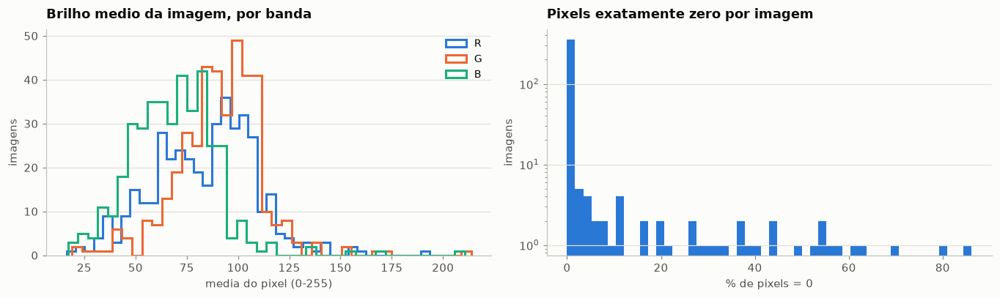

In [29]:
fig, axes = plt.subplots(1, 2, figsize=(12.5, 3.8))
for i, (nome, cor) in enumerate(zip(["R","G","B"], [V.CATEGORICAL[0], V.CATEGORICAL[1], V.CATEGORICAL[2]])):
    axes[0].hist(band_stats[f"mean_b{i}"], bins=40, histtype="step", lw=2, color=cor, label=nome)
axes[0].set_title("Brilho medio da imagem, por banda")
axes[0].set_xlabel("media do pixel (0-255)"); axes[0].set_ylabel("imagens")
axes[0].legend(title=None)

axes[1].hist(band_stats.frac_zero*100, bins=50, color=V.CATEGORICAL[0])
axes[1].set_title("Pixels exatamente zero por imagem")
axes[1].set_xlabel("% de pixels = 0"); axes[1].set_ylabel("imagens")
axes[1].set_yscale("log")
fig.tight_layout()

In [30]:
print("constantes de normalizacao (use estas, nao as do ImageNet):")
print(f"  mean = {[round(m/255,4) for m in mu]}")
print(f"  std  = {[round(s/255,4) for s in sd]}")
print(f"\nImageNet, para comparacao:")
print(f"  mean = [0.485, 0.456, 0.406]")
print(f"  std  = [0.229, 0.224, 0.225]")
print(f"\npixels zerados — media {band_stats.frac_zero.mean()*100:.1f}% por imagem, "
      f"maximo {band_stats.frac_zero.max()*100:.1f}%")
print(f"imagens com >20% de pixels zerados: {(band_stats.frac_zero>0.2).mean()*100:.1f}% da amostra")

constantes de normalizacao (use estas, nao as do ImageNet):
  mean = [np.float64(0.3293), np.float64(0.3571), np.float64(0.2693)]
  std  = [np.float64(0.1218), np.float64(0.1064), np.float64(0.1027)]

ImageNet, para comparacao:
  mean = [0.485, 0.456, 0.406]
  std  = [0.229, 0.224, 0.225]

pixels zerados — media 3.3% por imagem, maximo 86.2%
imagens com >20% de pixels zerados: 6.3% da amostra


---
## 9. Consistencia pre/pos dos rotulos

No xBD a mesma edificacao guarda o **mesmo `uid`** nas duas datas. Isso permite parear os
poligonos e medir quanto a geometria muda entre pre e pos.

In [31]:
sh = registration.shift_px
print(f"edificacoes pareadas por uid : {len(registration):,}")
print(f"deslocamento do centroide (px):")
print(f"  mediana : {sh.median():.2e}")
print(f"  p90     : {sh.quantile(.90):.4f}")
print(f"  p99     : {sh.quantile(.99):.4f}")
print(f"  maximo  : {sh.max():.2f}")
print(f"\nfracao com deslocamento > 1 px : {(sh > 1).mean()*100:.2f}%")
print(f"fracao com area identica        : {(registration.area_ratio.sub(1).abs() < 1e-9).mean()*100:.1f}%")

edificacoes pareadas por uid : 425,368
deslocamento do centroide (px):
  mediana : 3.72e-07
  p90     : 0.0060
  p99     : 0.9993
  maximo  : 16.64

fracao com deslocamento > 1 px : 1.00%
fracao com area identica        : 87.7%


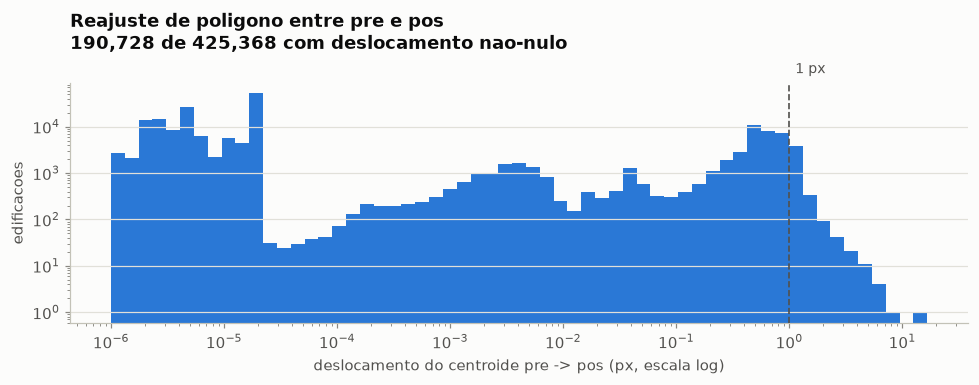

In [32]:
fig, ax = plt.subplots(figsize=(9, 3.6))
nz = sh[sh > 1e-6]
ax.hist(nz, bins=np.logspace(-6, np.log10(sh.max()), 60), color=V.CATEGORICAL[0])
ax.set_xscale("log"); ax.set_yscale("log")
ax.set_xlabel("deslocamento do centroide pre -> pos (px, escala log)")
ax.set_ylabel("edificacoes")
ax.set_title(f"Reajuste de poligono entre pre e pos\n{len(nz):,} de {len(sh):,} com deslocamento nao-nulo", pad=22)
V.ref_line(ax, 1, "1 px")
fig.tight_layout()

---
## 10. Distribuicao geografica

Cada evento cobre uma regiao compacta; o dataset inteiro sao 19 manchas espalhadas pelo globo.

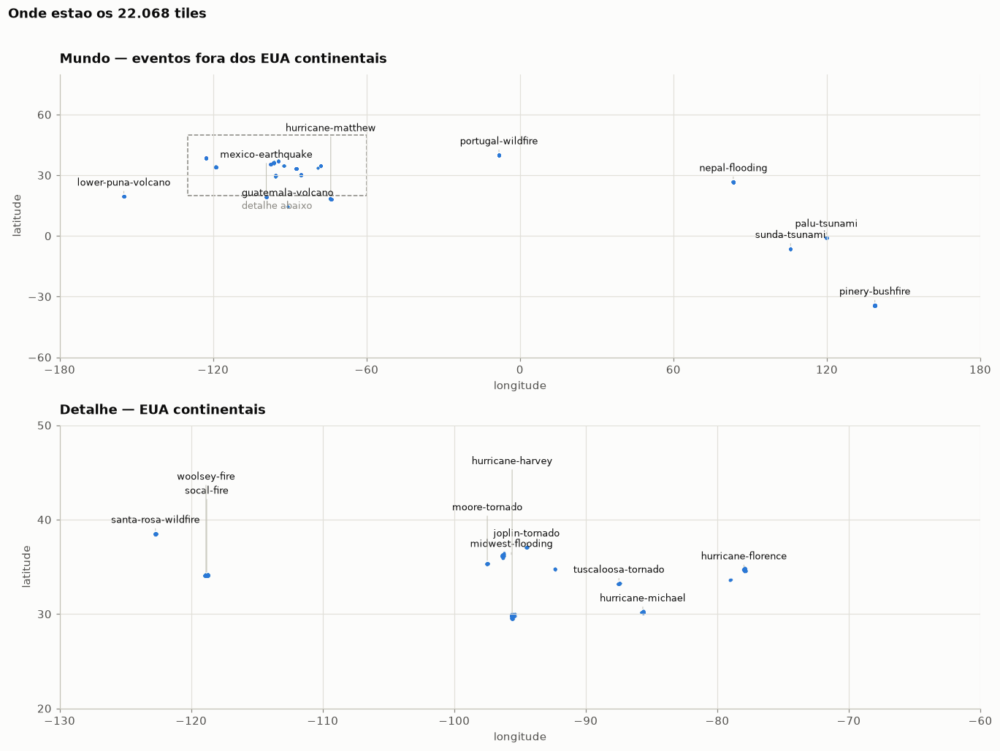

In [33]:
loc = post.groupby("disaster").agg(
    lon=("lon_center","mean"), lat=("lat_center","mean"),
    tiles=("stem","size"),
    span_km=("lon_center", lambda s: (s.max()-s.min())*111*np.cos(np.radians(post.loc[s.index,"lat_center"].mean()))))

def mapa(ax, xlim, ylim, rotular, titulo):
    """Serie unica (a cor nao carrega identidade); cada evento e rotulado diretamente."""
    ax.scatter(post.lon_center, post.lat_center, s=5, color=V.CATEGORICAL[0],
               alpha=0.30, linewidths=0)
    sub = loc.loc[[d for d in rotular]].sort_values("lat", ascending=False)
    # empilha rotulos verticalmente quando os eventos ficam proximos em latitude
    ocupado = []
    for d, r in sub.iterrows():
        dy = 10
        while any(abs(r.lat + dy*(ylim[1]-ylim[0])/260 - o) < (ylim[1]-ylim[0])*0.035 for o in ocupado):
            dy += 13
        ypos = r.lat + dy*(ylim[1]-ylim[0])/260
        ocupado.append(ypos)
        ax.annotate(d, (r.lon, r.lat), (r.lon, ypos), textcoords="data",
                    ha="center", fontsize=8.5, color=V.INK,
                    arrowprops=dict(arrowstyle="-", color=V.AXIS, lw=0.7,
                                    shrinkA=1, shrinkB=3))
    ax.set_xlim(*xlim); ax.set_ylim(*ylim)
    ax.set_xlabel("longitude"); ax.set_ylabel("latitude")
    ax.set_title(titulo)
    ax.grid(True, axis="both")

na = loc.index[(loc.lon.between(-130, -60)) & (loc.lat.between(20, 50))].tolist()
resto = [d for d in loc.index if d not in na]

fig, axes = plt.subplots(2, 1, figsize=(12.5, 9.5))
mapa(axes[0], (-180, 180), (-60, 80), resto, "Mundo — eventos fora dos EUA continentais")
axes[0].set_xticks(range(-180, 181, 60)); axes[0].set_yticks(range(-60, 81, 30))
# moldura do detalhe
axes[0].add_patch(plt.Rectangle((-130, 20), 70, 30, fill=False, edgecolor=V.MUTED, lw=1, ls="--"))
axes[0].annotate("detalhe abaixo", (-95, 20), (0, -12), textcoords="offset points",
                 ha="center", fontsize=8.5, color=V.MUTED)

mapa(axes[1], (-130, -60), (20, 50), na, "Detalhe — EUA continentais")
axes[1].set_xticks(range(-130, -59, 10)); axes[1].set_yticks(range(20, 51, 10))
fig.suptitle("Onde estao os 22.068 tiles", x=0.008, ha="left", fontsize=12,
             fontweight="bold", color=V.INK)
fig.tight_layout(rect=(0, 0, 1, 0.97))

In [34]:
loc.assign(span_km=loc.span_km.round(1)).sort_values("tiles", ascending=False)

,lon,lat,tiles,span_km
disaster,,,,
portugal-wildfire,-8.212475,39.919727,1869,18.9
pinery-bushfire,138.781368,-34.395718,1845,19.8
socal-fire,-118.816200,34.090800,1403,20.6
woolsey-fire,-118.869108,34.083780,878,20.0
nepal-flooding,83.419796,26.623611,619,29.1
hurricane-michael,-85.659983,30.191325,550,16.1
hurricane-florence,-77.968981,34.634896,546,111.1
hurricane-harvey,-95.593194,29.725039,522,32.5
midwest-flooding,-95.653037,35.954567,445,366.2


In [35]:
cobertura = pd.crosstab(images.disaster, images.split)
cobertura = cobertura[["tier1","tier3","hold","test"]]
cobertura["tipo"] = images.groupby("disaster").disaster_type.first()
cobertura["so_treino"] = (cobertura[["hold","test"]].sum(1) == 0)
print(f"desastres presentes em avaliacao (hold/test): {(~cobertura.so_treino).sum()}")
print(f"desastres exclusivos de treino (tier3)      : {cobertura.so_treino.sum()}")
print(f"cenas duplicadas entre splits               : {images.groupby('scene_id').split.nunique().gt(1).sum()}")
cobertura.sort_values(["so_treino","tier1"], ascending=[True, False])

desastres presentes em avaliacao (hold/test): 10
desastres exclusivos de treino (tier3)      : 9
cenas duplicadas entre splits               : 0


split,tier1,tier3,hold,test,tipo,so_treino
disaster,,,,,,
socal-fire,1646,0,546,614,fire,False
hurricane-michael,686,0,218,196,wind,False
hurricane-florence,638,0,238,216,flooding,False
hurricane-harvey,638,0,190,216,flooding,False
midwest-flooding,558,0,172,160,flooding,False
hurricane-matthew,476,0,188,146,wind,False
santa-rosa-wildfire,452,0,154,148,fire,False
mexico-earthquake,242,0,68,76,earthquake,False
palu-tsunami,226,0,82,84,tsunami,False


In [36]:
rows = []
for d, g in post.groupby("disaster"):
    tr = g[g.split == "tier1"][["lon_center","lat_center"]].to_numpy()
    ev = g[g.split.isin(["hold","test"])][["lon_center","lat_center"]].to_numpy()
    if len(tr) == 0 or len(ev) == 0:
        continue
    lat0 = np.radians(g.lat_center.mean())
    A = np.c_[tr[:,0]*np.cos(lat0)*111320, tr[:,1]*110574]
    B = np.c_[ev[:,0]*np.cos(lat0)*111320, ev[:,1]*110574]
    dist = np.sqrt(((B[:,None,:] - A[None,:,:])**2).sum(-1)).min(1)
    rows.append({"disaster": d, "tiles_aval": len(B),
                 "dist_mediana_m": np.median(dist),
                 "% a <500m do treino": (dist < 500).mean()*100,
                 "% a <1km do treino":  (dist < 1000).mean()*100})
viz = pd.DataFrame(rows).set_index("disaster").sort_values("% a <500m do treino", ascending=False)
viz.round(1)

,tiles_aval,dist_mediana_m,% a <500m do treino,% a <1km do treino
disaster,,,,
socal-fire,580,467.5,97.1,100.0
hurricane-matthew,167,496.7,94.6,100.0
hurricane-michael,207,476.0,84.5,97.6
santa-rosa-wildfire,151,457.1,76.2,95.4
mexico-earthquake,72,495.5,70.8,93.1
hurricane-florence,227,466.9,68.3,85.9
hurricane-harvey,203,477.4,68.0,83.3
midwest-flooding,166,465.9,53.0,87.3
palu-tsunami,83,509.8,2.4,94.0


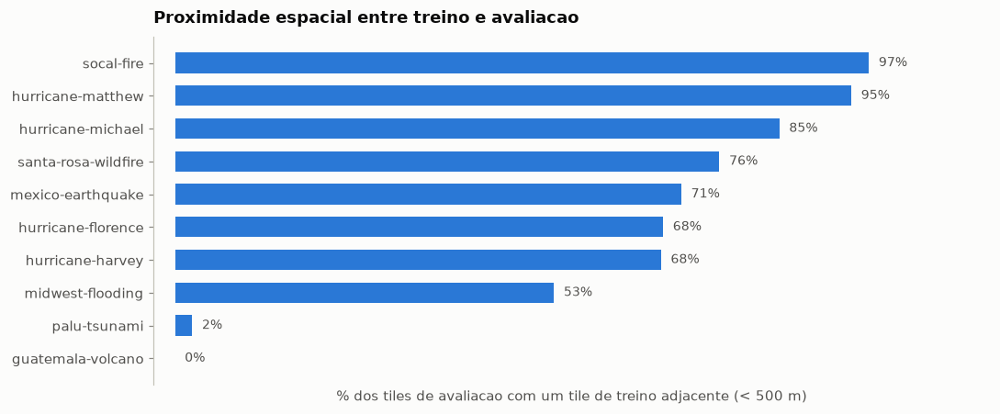

In [37]:
fig, ax = plt.subplots(figsize=(10, 4.2))
v = viz["% a <500m do treino"].sort_values()
y = np.arange(len(v))
b = ax.barh(y, v.values, height=0.62, color=V.CATEGORICAL[0])
ax.set_yticks(y, v.index)
ax.set_xlim(-3, 114)
ax.set_xlabel("% dos tiles de avaliacao com um tile de treino adjacente (< 500 m)")
ax.set_title("Proximidade espacial entre treino e avaliacao")
V.bar_labels(ax, b, fmt="{:.0f}%", pad=7)
ax.set_xticks([]); ax.grid(False)
ax.spines["bottom"].set_visible(False)
fig.tight_layout()

In [38]:
print(f"mediana da distancia ao tile de treino mais proximo: "
      f"{viz.dist_mediana_m.median():.0f} m  (lado do tile ~ 460 m)")
print(f"eventos com >65% dos tiles de avaliacao adjacentes ao treino: "
      f"{(viz['% a <500m do treino'] > 65).sum()} de {len(viz)}")

mediana da distancia ao tile de treino mais proximo: 477 m  (lado do tile ~ 460 m)
eventos com >65% dos tiles de avaliacao adjacentes ao treino: 7 de 10


In [39]:
compart = images.groupby("catalog_id").split.nunique()
print(f"catalog_id (capturas de satelite) presentes em mais de um split: "
      f"{compart.gt(1).sum()} de {len(compart)}")
print("\nsugestao de split honesto — agrupar por evento, ex.:")
print("  from sklearn.model_selection import GroupKFold")
print("  GroupKFold(n_splits=5).split(X, y, groups=images.disaster)")

catalog_id (capturas de satelite) presentes em mais de um split: 42 de 66

sugestao de split honesto — agrupar por evento, ex.:
  from sklearn.model_selection import GroupKFold
  GroupKFold(n_splits=5).split(X, y, groups=images.disaster)


---
## 12. Integridade dos arquivos



In [40]:
integridade = pd.Series({
    "GeoTIFF esperados":              f"{len(images):,}",
    "GeoTIFF abertos com sucesso":    f"{images.tif_exists.sum():,}",
    "GeoTIFF ilegiveis":              f"{(~images.tif_exists).sum():,}",
    "arquivos de tamanho zero":       "0",
    "labels JSON com erro de parse":  "0",
    "poligonos lidos":                f"{len(buildings):,}",
    "geometrias vazias / invalidas":  f"{int(images.n_invalid_geom.sum()):,}",
    "poligonos auto-intersectantes":  f"{int((~buildings.is_valid).sum()):,}",
    "cenas sem par pre/pos":          f"{(images.groupby('scene_id').phase.nunique() != 2).sum():,}",
}, name="valor").to_frame()
integridade

,valor
GeoTIFF esperados,"22,068"
GeoTIFF abertos com sucesso,"22,068"
GeoTIFF ilegiveis,0
arquivos de tamanho zero,0
labels JSON com erro de parse,0
poligonos lidos,"850,736"
geometrias vazias / invalidas,0
poligonos auto-intersectantes,80
cenas sem par pre/pos,0


---
## 13. Exemplos

Pares pre/pos com os poligonos sobrepostos. No painel *pre* todos os poligonos sao iguais
(so localizacao); no *pos* a cor e a hachura indicam a severidade.

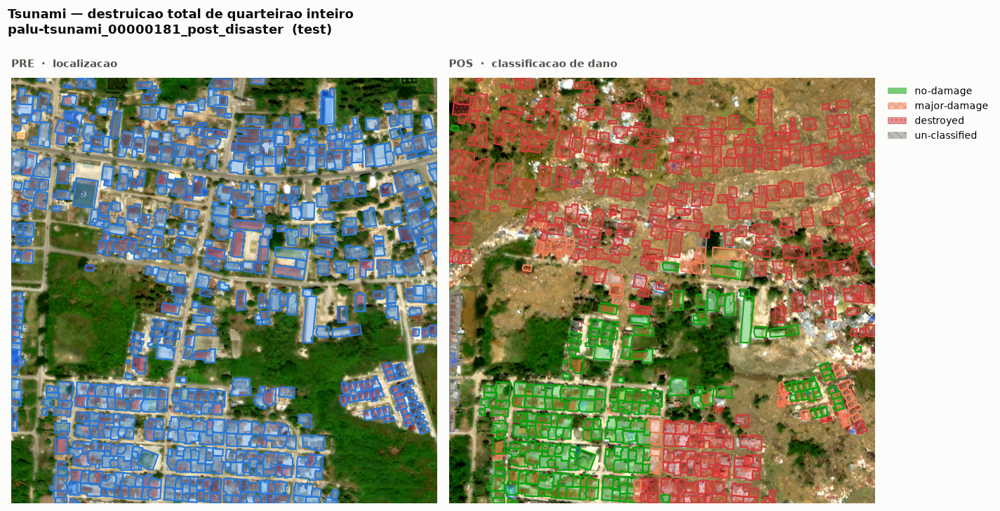

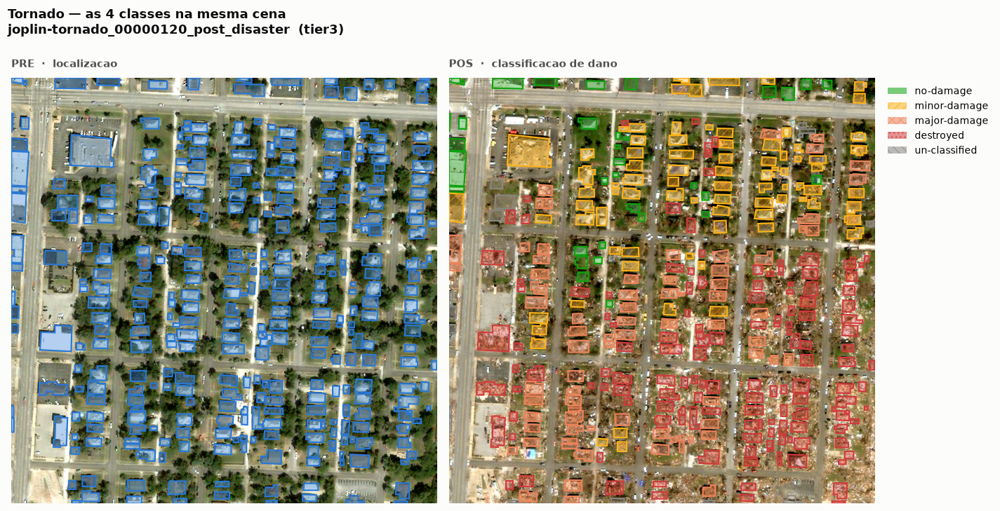

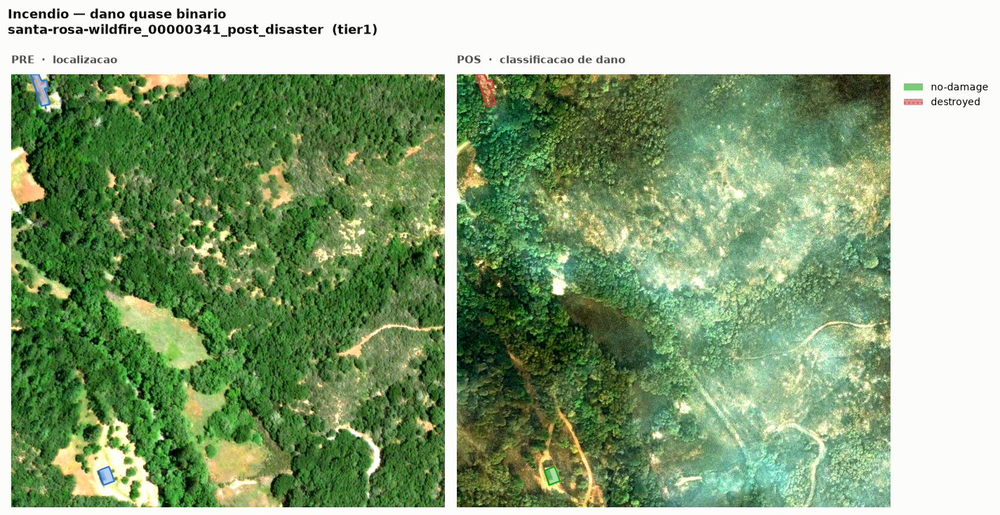

In [41]:
exemplos = [
    ("palu-tsunami_00000181_post_disaster",      "test",  "Tsunami — destruicao total de quarteirao inteiro"),
    ("joplin-tornado_00000120_post_disaster",    "tier3", "Tornado — as 4 classes na mesma cena"),
    ("santa-rosa-wildfire_00000341_post_disaster","tier1","Incendio — dano quase binario"),
]
for stem, split, titulo in exemplos:
    V.show_scene(stem, split, GEO, title=f"{titulo}\n{stem}  ({split})")
    plt.show()

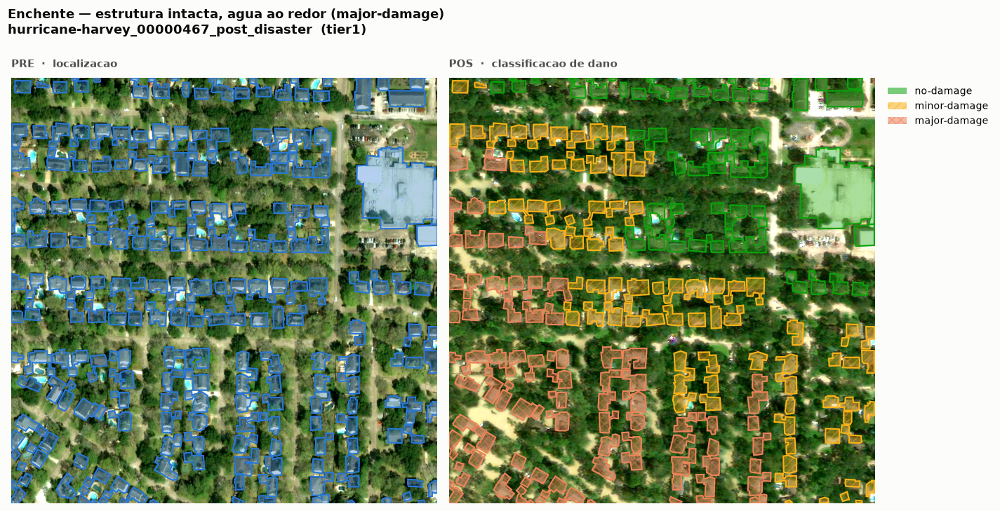

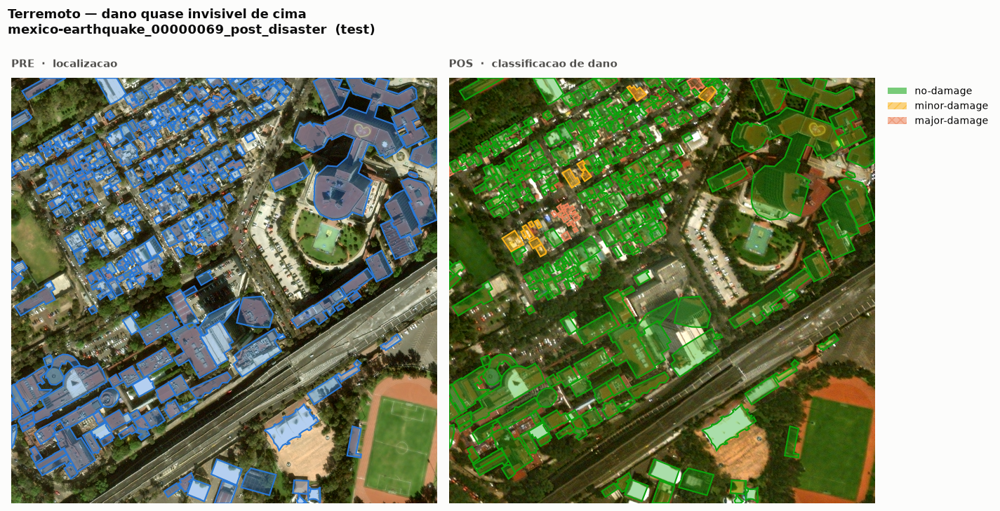

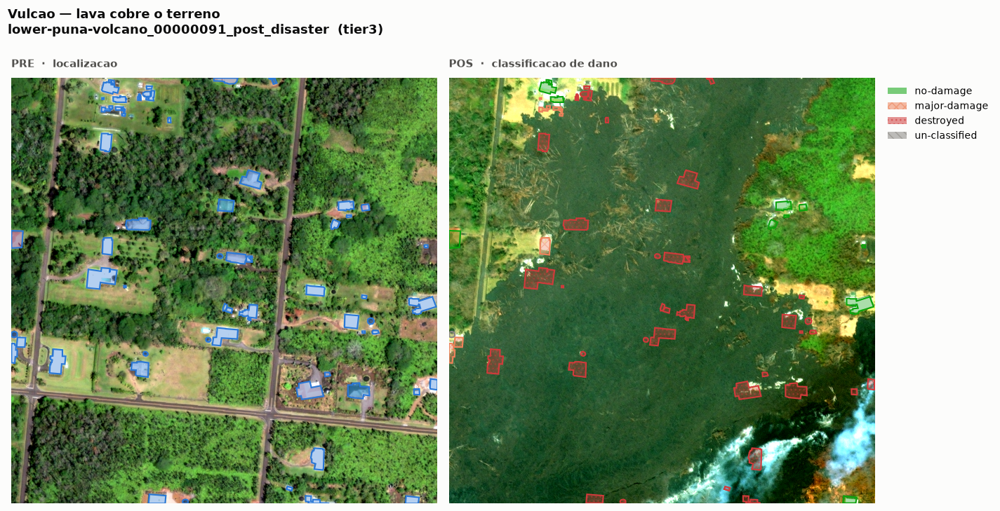

In [42]:
exemplos2 = [
    ("hurricane-harvey_00000467_post_disaster",  "tier1", "Enchente — estrutura intacta, agua ao redor (major-damage)"),
    ("mexico-earthquake_00000069_post_disaster", "test",  "Terremoto — dano quase invisivel de cima"),
    ("lower-puna-volcano_00000091_post_disaster","tier3", "Vulcao — lava cobre o terreno"),
]
for stem, split, titulo in exemplos2:
    V.show_scene(stem, split, GEO, title=f"{titulo}\n{stem}  ({split})")
    plt.show()

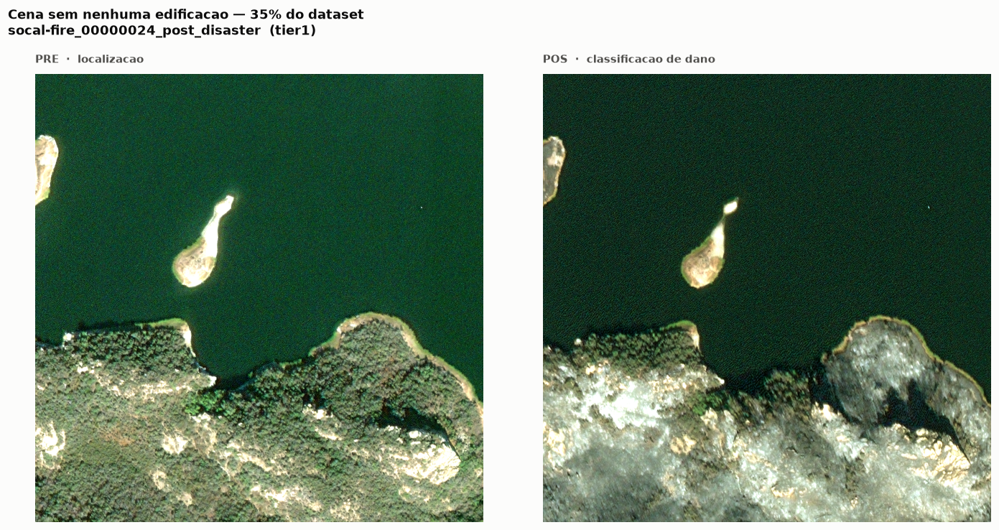

In [43]:
# Exemplos dos casos dificeis: cenas vazias e imagens com borda sem dado
vazia = post[post.n_buildings == 0].sample(1, random_state=7).iloc[0]
V.show_scene(vazia.stem, vazia.split, GEO,
             title=f"Cena sem nenhuma edificacao — 35% do dataset\n{vazia.stem}  ({vazia.split})")
plt.show()